<a href="https://colab.research.google.com/github/Deeptanshu-Paul/SWYNEX-Modeling-and-Evaluation/blob/main/Modeling_and_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

In [2]:
from google.colab import files
uploaded = files.upload()   # a "Choose Files" button appears; select BOTH CSVs

train = pd.read_csv("Training_clean.csv")
test  = pd.read_csv("Testing_clean.csv")

# drop any accidental empty columns
train = train.loc[:, ~train.columns.str.contains("^Unnamed")]
test  = test.loc[:, ~test.columns.str.contains("^Unnamed")]

print(train.shape, test.shape)
train.head()

Saving Testing_clean.csv to Testing_clean.csv
Saving Training_clean.csv to Training_clean.csv
(4920, 133) (42, 133)


,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,blackheads,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Fungal infection


In [3]:
target = "prognosis"
print("Classes:", train[target].nunique())
print("Duplicate rows in train:", train.duplicated().sum())

train_u = train.drop_duplicates().reset_index(drop=True)
print("Unique rows after dedup:", train_u.shape)
print(train_u[target].value_counts().describe())

Classes: 41
Duplicate rows in train: 4616
Unique rows after dedup: (304, 133)
count    41.000000
mean      7.414634
std       1.702581
min       5.000000
25%       6.000000
50%       7.000000
75%       9.000000
max      10.000000
Name: count, dtype: float64


In [4]:
X_raw, y_raw = train.drop(columns=[target]), train[target]
Xtr, Xte, ytr, yte = train_test_split(X_raw, y_raw, test_size=0.2,
                                      random_state=42, stratify=y_raw)
leaky = RandomForestClassifier(random_state=42).fit(Xtr, ytr)
print("Accuracy with duplicates left in:", accuracy_score(yte, leaky.predict(Xte)))

Accuracy with duplicates left in: 1.0


In [5]:
X = train_u.drop(columns=[target])
y = train_u[target]

min_count = y.value_counts().min()
strat = y if min_count >= 2 else None   # stratify only if every class has 2+ rows

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=strat)

X_test, y_test = test.drop(columns=[target]), test[target]
print(X_train.shape, X_val.shape, X_test.shape)

(243, 132) (61, 132) (42, 132)


In [6]:
baseline = LogisticRegression(max_iter=2000)
baseline.fit(X_train, y_train)

LogisticRegression(max_iter=2000)

In [7]:
def evaluate(model, X, y, name):
    pred = model.predict(X)
    print(f"--- {name} ---")
    print("Accuracy       :", round(accuracy_score(y, pred), 4))
    print("Precision (mac):", round(precision_score(y, pred, average='macro', zero_division=0), 4))
    print("Recall (mac)   :", round(recall_score(y, pred, average='macro', zero_division=0), 4))
    print("F1 (macro)     :", round(f1_score(y, pred, average='macro', zero_division=0), 4))
    return pred

val_pred  = evaluate(baseline, X_val,  y_val,  "Baseline | validation split")
test_pred = evaluate(baseline, X_test, y_test, "Baseline | official test set")

--- Baseline | validation split ---
Accuracy       : 1.0
Precision (mac): 1.0
Recall (mac)   : 1.0
F1 (macro)     : 1.0
--- Baseline | official test set ---
Accuracy       : 1.0
Precision (mac): 1.0
Recall (mac)   : 1.0
F1 (macro)     : 1.0


In [8]:
print("Unique train shape:", train_u.shape)
print("Train / Val / Test:", X_train.shape, X_val.shape, X_test.shape)

# rows that appear in BOTH train and validation (should be 0)
print("Shared train/val rows:", len(X_train.drop_duplicates().merge(X_val.drop_duplicates(), how="inner")))

# official test rows that also appear in training (informational)
print("Test rows also in train:", len(X_test.merge(X_train.drop_duplicates(), how="inner")))

Unique train shape: (304, 133)
Train / Val / Test: (243, 132) (61, 132) (42, 132)
Shared train/val rows: 0
Test rows also in train: 32


In [9]:
models = {
    "Logistic Regression (baseline)": baseline,
    "Bernoulli Naive Bayes": BernoulliNB(),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_val)
    rows.append({"Model": name,
                 "Val Accuracy": accuracy_score(y_val, p),
                 "Val Macro F1": f1_score(y_val, p, average="macro", zero_division=0),
                 "Test Accuracy": accuracy_score(y_test, m.predict(X_test))})
results = pd.DataFrame(rows).round(4)
results

,Model,Val Accuracy,Val Macro F1,Test Accuracy
0,Logistic Regression (baseline),1.0000,1.0000,1.0000
1,Bernoulli Naive Bayes,0.9672,0.9545,0.9762
2,Random Forest,1.0000,1.0000,1.0000


In [10]:
n_splits = int(min(5, min_count))
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
scores = cross_val_score(baseline, X, y, cv=cv, scoring="accuracy")
print(f"{n_splits}-fold CV accuracy: {scores.mean():.3f} +/- {scores.std():.3f}")

5-fold CV accuracy: 1.000 +/- 0.000


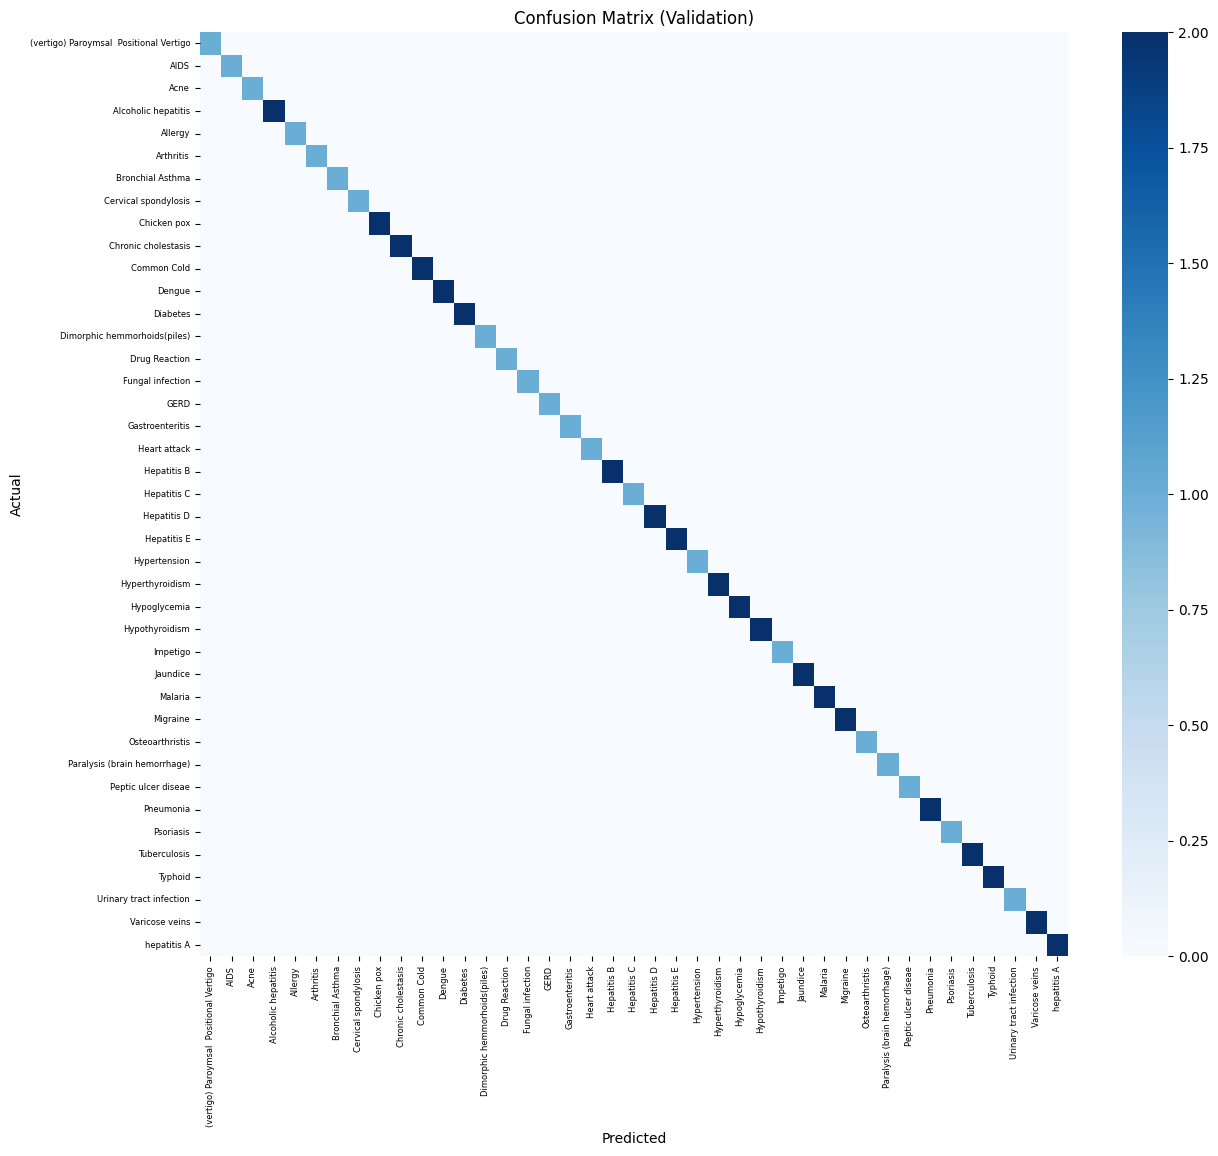

In [11]:
best = models["Random Forest"]
cm = confusion_matrix(y_val, best.predict(X_val), labels=best.classes_)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap="Blues", xticklabels=best.classes_, yticklabels=best.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix (Validation)")
plt.xticks(fontsize=6); plt.yticks(fontsize=6)
plt.show()

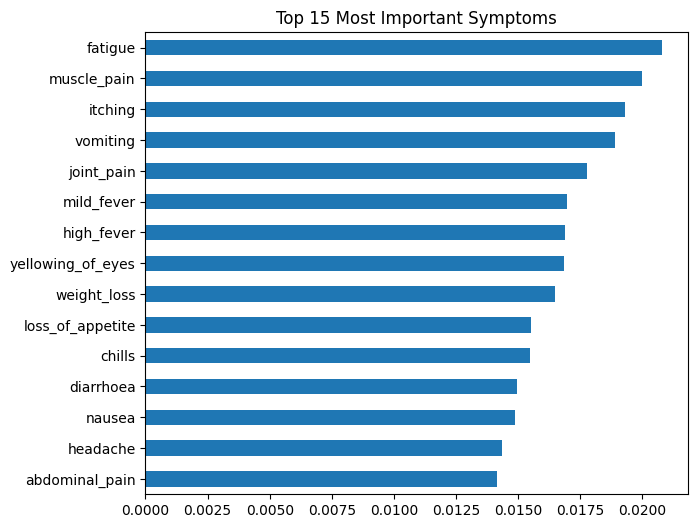

In [12]:
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values(ascending=False)[:15]
imp.sort_values().plot(kind="barh", figsize=(7, 6), title="Top 15 Most Important Symptoms")
plt.show()

## Results Summary

| Model | Val Accuracy | Val Macro F1 | Test Accuracy |
|---|---|---|---|
| Logistic Regression (baseline) | [ ] | [ ] | [ ] |
| Bernoulli Naive Bayes | [ ] | [ ] | [ ] |
| Random Forest | [ ] | [ ] | [ ] |

Cross-validation accuracy (baseline): [mean] ± [std]

## Key Insight
Leaving duplicates in the data inflated accuracy because identical rows appeared in
both train and test. After removing duplicates before splitting, scores were still
very high ([value]), suggesting each disease has an almost deterministic symptom
pattern. This points to a clean, likely synthetic dataset rather than an unusually
strong model.

## Limitations
1. **Heavy duplication:** only [N] unique symptom patterns exist in 4,920 rows.
2. **Tiny official test set:** 42 rows (about one per disease), so one error changes
   accuracy by about 2.4 points.
3. **Train/test overlap:** many test patterns repeat training patterns, so the test
   score reflects memorization more than generalization.
4. **Binary symptoms only:** no severity, duration, age or medical history, and several
   diseases share symptoms.
5. **Likely synthetic data:** results may not transfer to real patients.
6. **Not for medical use:** this is a learning exercise, not a diagnostic tool.

## Next Steps
Hyperparameter tuning (GridSearchCV), top-3 probability predictions, testing on
real clinical data, and adding patient metadata.